In [ ]:
import pandas as pd

In [ ]:
regseason = pd.read_csv("MRegularSeasonDetailedResults.csv")

regseason.head(10)

winners = regseason[["Season","DayNum","WTeamID","WScore","WLoc",'WFGM','WFGA','WFGM3','WFGA3','WFTM','WFTA','WOR','WDR','WAst','WTO','WStl','WBlk','WPF']].copy()
winners = winners.rename(
    columns={
        "WTeamID":"TeamID",
        "WScore":"Score",
        "WFGM":"FGM",
        "WFGA":"FGA",
        "WFGM3":"FGM3",
        "WFGA3":"FGA3",
        "WFTM":"FTM",
        "WFTA":"FTA",
        "WOR":"OR",
        "WDR":"DR",
        "WAst":"Ast",
        "WTO":"TO",
        "WStl":"Stl",
        "WBlk":"Blk",
        "WPF":"PF"
    }
)
losers = regseason[["Season","DayNum","LTeamID","LScore","WLoc",'LFGM','LFGA','LFGM3','LFGA3','LFTM','LFTA','LOR','LDR','LAst','LTO','LStl','LBlk','LPF']].copy()
losers = losers.rename(
    columns = {
        "LTeamID":"TeamID",
        "LScore":"Score",
        "LFGM":"FGM",
        "LFGA":"FGA",
        "LFGM3":"FGM3",
        "LFGA3":"FGA3",
        "LFTM":"FTM",
        "LFTA":"FTA",
        "LOR":"OR",
        "LDR":"DR",
        "LAst":"Ast",
        "LTO":"TO",
        "LStl":"Stl",
        "LBlk":"Blk",
        "LPF":"PF"
    }
)

totals = pd.concat([winners,losers])

seasonstats = totals.groupby(
    ["Season","TeamID"]
).agg(
        Games=("DayNum","count"),
        Points=("Score","sum"),
        FGM=("FGM","sum"),
        FGA=("FGA","sum"),
        FGM3=("FGM3","sum"),
        FGA3=("FGA3","sum"),
        FTM=("FTM","sum"),
        FTA=("FTA","sum"),
        OR=("OR","sum"),
        DR=("DR","sum"),
        Ast=("Ast","sum"),
        TO=("TO","sum"),
        Stl=("Stl","sum"),
        Blk=("Blk","sum"),
        PF=("PF","sum")
).reset_index()

seasonstats["FG%"] = seasonstats["FGM"]/seasonstats["FGA"]
seasonstats["3P%"] = seasonstats["FGM3"]/seasonstats["FGA3"]
seasonstats["FT%"] = seasonstats["FTM"]/seasonstats["FTA"]
seasonstats["ORtg"] = seasonstats["OR"]/(seasonstats["OR"]+seasonstats["DR"])
seasonstats["DRtg"] = seasonstats["DR"]/(seasonstats["OR"]+seasonstats["DR"])

seasonstats["PPG"] = seasonstats["Points"]/seasonstats["Games"]
seasonstats["FGMPG"] = seasonstats["FGM"]/seasonstats["Games"]
seasonstats["FGAPG"] = seasonstats["FGA"]/seasonstats["Games"]
seasonstats["FGM3PG"] = seasonstats["FGM3"]/seasonstats["Games"]
seasonstats["FGA3PG"] = seasonstats["FGA3"]/seasonstats["Games"]
seasonstats["FTMPG"] = seasonstats["FTM"]/seasonstats["Games"]
seasonstats["FTAPG"] = seasonstats["FTA"]/seasonstats["Games"]
seasonstats["ORPG"] = seasonstats["OR"]/seasonstats["Games"]
seasonstats["DRPG"] = seasonstats["DR"]/seasonstats["Games"]
seasonstats["ASTPG"] = seasonstats["Ast"]/seasonstats["Games"]
seasonstats["TOPG"] = seasonstats["TO"]/seasonstats["Games"]
seasonstats["STLPG"] = seasonstats["Stl"]/seasonstats["Games"]
seasonstats["BLKG"] = seasonstats["Blk"]/seasonstats["Games"]
seasonstats["PFPG"] = seasonstats["PF"]/seasonstats["Games"]

seasonstats.head()

,Season,TeamID,Games,Points,FGM,FGA,FGM3,FGA3,FTM,FTA,...,FGA3PG,FTMPG,FTAPG,ORPG,DRPG,ASTPG,TOPG,STLPG,BLKG,PFPG
0,2003,1102,28,1603,536,1114,219,583,312,479,...,20.821429,11.142857,17.107143,4.178571,16.821429,13.000000,11.428571,5.964286,1.785714,18.750000
1,2003,1103,27,2127,733,1508,147,434,514,698,...,16.074074,19.037037,25.851852,9.777778,19.925926,15.222222,12.629630,7.259259,2.333333,19.851852
2,2003,1104,28,1940,673,1601,178,556,416,586,...,19.857143,14.857143,20.928571,13.571429,23.928571,12.107143,13.285714,6.607143,3.785714,18.035714
3,2003,1105,26,1866,634,1602,197,540,401,568,...,20.769231,15.423077,21.846154,13.500000,23.115385,14.538462,18.653846,9.307692,2.076923,20.230769
4,2003,1106,28,1781,656,1548,171,494,298,461,...,17.642857,10.642857,16.464286,12.285714,23.857143,11.678571,17.035714,8.357143,3.142857,18.178571


In [ ]:
correlation_variables = [
    "Games",
    "Points",
    "FGM",
    "FGA",
    "FGM3",
    "FGA3",
    "FTM",
    "FTA",
    "OR",
    "DR",
    "Ast",
    "TO",
    "Stl",
    "Blk",
    "PF",
    "FG%",
    "3P%",
    "FT%",
    "ORtg",
    "DRtg",
    "PPG",
    "FGMPG",
    "FGAPG",
    "FGM3PG",
    "FGA3PG",
    "FTMPG",
    "FTAPG",
    "ORPG",
    "DRPG",
    "ASTPG",
    "TOPG",
    "STLPG",
    "BLKG",
    "PFPG"
]

correlation_matrix = seasonstats[correlation_variables].corr()

display(correlation_matrix)

,Games,Points,FGM,FGA,FGM3,FGA3,FTM,FTA,OR,DR,...,FGA3PG,FTMPG,FTAPG,ORPG,DRPG,ASTPG,TOPG,STLPG,BLKG,PFPG
Games,1.000000,0.803872,0.784529,0.845528,0.472764,0.489361,0.602763,0.602182,0.475742,0.794811,...,0.036156,0.157481,0.127804,0.106015,0.188175,0.164092,-0.267202,0.021983,0.209982,-0.150312
Points,0.803872,1.000000,0.972119,0.894467,0.649970,0.597738,0.722100,0.664935,0.427080,0.795396,...,0.263316,0.416999,0.323930,0.130966,0.403093,0.500680,-0.359906,0.142080,0.293374,-0.130498
FGM,0.784529,0.972119,1.000000,0.908087,0.596794,0.549029,0.579612,0.538649,0.415942,0.779477,...,0.218140,0.252596,0.179696,0.126753,0.398265,0.532780,-0.369566,0.160374,0.311916,-0.185728
FGA,0.845528,0.894467,0.908087,1.000000,0.568640,0.615243,0.552871,0.543118,0.539736,0.776081,...,0.261611,0.184928,0.148961,0.243031,0.327592,0.305191,-0.325696,0.169023,0.285112,-0.089838
FGM3,0.472764,0.649970,0.596794,0.568640,1.000000,0.941856,0.208907,0.115121,-0.024272,0.447549,...,0.827579,-0.022054,-0.151774,-0.231779,0.205848,0.402844,-0.442830,-0.027120,0.010034,-0.228077
FGA3,0.489361,0.597738,0.549029,0.615243,0.941856,1.000000,0.178072,0.105750,0.003699,0.436172,...,0.885549,-0.069697,-0.173297,-0.206588,0.170655,0.276351,-0.431270,0.000127,0.014649,-0.211932
FTM,0.602763,0.722100,0.579612,0.552871,0.208907,0.178072,1.000000,0.955059,0.490396,0.600325,...,-0.111121,0.879112,0.808173,0.289218,0.308545,0.193957,-0.081065,0.117252,0.252123,0.146967
FTA,0.602182,0.664935,0.538649,0.543118,0.115121,0.105750,0.955059,1.000000,0.598620,0.597020,...,-0.193103,0.824675,0.865039,0.411890,0.303815,0.145616,0.032056,0.159538,0.286889,0.216590
OR,0.475742,0.427080,0.415942,0.539736,-0.024272,0.003699,0.490396,0.598620,1.000000,0.461252,...,-0.242646,0.326546,0.447341,0.920609,0.221111,0.119304,0.242780,0.242343,0.322827,0.250484
DR,0.794811,0.795396,0.779477,0.776081,0.447549,0.436172,0.600325,0.597020,0.461252,1.000000,...,0.086086,0.272515,0.245474,0.171422,0.742905,0.310326,-0.188677,-0.123595,0.364962,-0.168935


In [ ]:
regseason.head()

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT,WFGM,WFGA,...,LFGA3,LFTM,LFTA,LOR,LDR,LAst,LTO,LStl,LBlk,LPF
0,2003,10,1104,68,1328,62,N,0,27,58,...,10,16,22,10,22,8,18,9,2,20
1,2003,10,1272,70,1393,63,N,0,26,62,...,24,9,20,20,25,7,12,8,6,16
2,2003,11,1266,73,1437,61,N,0,24,58,...,26,14,23,31,22,9,12,2,5,23
3,2003,11,1296,56,1457,50,N,0,18,38,...,22,8,15,17,20,9,19,4,3,23
4,2003,11,1400,77,1208,71,N,0,30,61,...,16,17,27,21,15,12,10,7,1,14


In [ ]:
tourney = pd.read_csv("MNCAATourneyCompactResults.csv")

tourney = tourney.where(tourney["Season"] >= 2003).reset_index(drop=True)
tourney.dropna(inplace=True)
tourney.reset_index(drop=True,inplace=True)

tourney["Season"] = tourney["Season"].astype(int)
tourney["WTeamID"] = tourney["WTeamID"].astype(int)
tourney["LTeamID"] = tourney["LTeamID"].astype(int)

tourney

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT
0,2003,134.0,1421,92.0,1411,84.0,N,1.0
1,2003,136.0,1112,80.0,1436,51.0,N,0.0
2,2003,136.0,1113,84.0,1272,71.0,N,0.0
3,2003,136.0,1141,79.0,1166,73.0,N,0.0
4,2003,136.0,1143,76.0,1301,74.0,N,1.0
...,...,...,...,...,...,...,...,...
1444,2025,146.0,1120,70.0,1277,64.0,N,0.0
1445,2025,146.0,1222,69.0,1397,50.0,N,0.0
1446,2025,152.0,1196,79.0,1120,73.0,N,0.0
1447,2025,152.0,1222,70.0,1181,67.0,N,0.0


In [ ]:
odds = tourney[tourney.index % 2 == 1].copy()
#odds the winning team will be "team 1"

odds = odds[["Season","DayNum","WTeamID","LTeamID"]].copy()
odds = odds.rename(
    columns={
        "WTeamID":"Team1",
        "LTeamID":"Team2"
    }
)

odds["team1_w"] = 1

evens = tourney[tourney.index % 2 == 0].copy()
#evens the losing team will be "team1"

evens = evens[["Season","DayNum","WTeamID","LTeamID"]].copy()
evens = evens.rename(
    columns={
        "WTeamID":"Team2",
        "LTeamID":"Team1"
    })

evens = evens[["Season","DayNum","Team1","Team2"]].copy()
evens["team1_w"] = 0

matchups = pd.concat([odds,evens])
matchups

,Season,DayNum,Team1,Team2,team1_w
1,2003,136.0,1112,1436,1
3,2003,136.0,1141,1166,1
5,2003,136.0,1163,1140,1
7,2003,136.0,1211,1153,1
9,2003,136.0,1242,1429,1
...,...,...,...,...,...
1440,2025,144.0,1279,1277,0
1442,2025,145.0,1104,1181,0
1444,2025,146.0,1277,1120,0
1446,2025,152.0,1120,1196,0


In [ ]:
matchups = matchups.merge(
    seasonstats,
    how="left",
    left_on=["Season","Team1"],
    right_on=["Season","TeamID"]
).merge(
    seasonstats,
    how="left",
    left_on=["Season","Team2"],
    right_on=["Season","TeamID"],
    suffixes=["_1","_2"]
)

matchups = matchups.drop(columns=["TeamID_1","TeamID_2"])
matchups.head()

,Season,DayNum,Team1,Team2,team1_w,Games_1,Points_1,FGM_1,FGA_1,FGM3_1,...,FGA3PG_2,FTMPG_2,FTAPG_2,ORPG_2,DRPG_2,ASTPG_2,TOPG_2,STLPG_2,BLKG_2,PFPG_2
0,2003,136.0,1112,1436,1,28,2386,849,1840,197,...,15.482759,12.862069,19.551724,12.965517,25.724138,14.206897,14.068966,6.862069,2.965517,15.896552
1,2003,136.0,1141,1166,1,29,2301,772,1528,198,...,20.484848,13.878788,20.030303,10.878788,23.181818,16.818182,13.363636,8.393939,4.454545,17.272727
2,2003,136.0,1163,1140,1,30,2401,886,1866,182,...,16.129032,18.193548,24.161290,10.870968,24.419355,13.419355,13.741935,6.935484,2.516129,21.419355
3,2003,136.0,1211,1153,1,31,2389,808,1719,222,...,19.500000,14.857143,21.535714,12.142857,23.392857,12.285714,10.607143,5.178571,4.250000,18.964286
4,2003,136.0,1242,1429,1,30,2440,907,1869,144,...,12.133333,14.533333,20.233333,12.633333,22.366667,13.900000,12.233333,5.066667,2.000000,16.100000


In [ ]:
matchups.shape

(1449, 73)

In [ ]:
newmatchups = pd.read_csv("2026matchups.csv")
newmatchups["team_name"] = newmatchups["team_name"].str.lower()

team_ids = pd.read_csv("MTeamSpellings.csv")

newmatchups = newmatchups.merge(
    team_ids,
    how="left",
    left_on=["team_name"],
    right_on=["TeamNameSpelling"]
).drop(columns=["TeamNameSpelling"])


display(newmatchups[newmatchups["TeamID"].isnull()])

newmatchups

,season,team_name,TeamID


,season,team_name,TeamID
0,2026,duke,1181
1,2026,siena,1373
2,2026,ohio state,1326
3,2026,tcu,1395
4,2026,st. john's,1385
...,...,...,...
59,2026,wright state,1460
60,2026,kentucky,1246
61,2026,santa clara,1365
62,2026,iowa state,1235


In [ ]:
matchups.head()

,Season,DayNum,Team1,Team2,team1_w,Games_1,Points_1,FGM_1,FGA_1,FGM3_1,...,FGA3PG_2,FTMPG_2,FTAPG_2,ORPG_2,DRPG_2,ASTPG_2,TOPG_2,STLPG_2,BLKG_2,PFPG_2
0,2003,136.0,1112,1436,1,28,2386,849,1840,197,...,15.482759,12.862069,19.551724,12.965517,25.724138,14.206897,14.068966,6.862069,2.965517,15.896552
1,2003,136.0,1141,1166,1,29,2301,772,1528,198,...,20.484848,13.878788,20.030303,10.878788,23.181818,16.818182,13.363636,8.393939,4.454545,17.272727
2,2003,136.0,1163,1140,1,30,2401,886,1866,182,...,16.129032,18.193548,24.161290,10.870968,24.419355,13.419355,13.741935,6.935484,2.516129,21.419355
3,2003,136.0,1211,1153,1,31,2389,808,1719,222,...,19.500000,14.857143,21.535714,12.142857,23.392857,12.285714,10.607143,5.178571,4.250000,18.964286
4,2003,136.0,1242,1429,1,30,2440,907,1869,144,...,12.133333,14.533333,20.233333,12.633333,22.366667,13.900000,12.233333,5.066667,2.000000,16.100000


In [ ]:
X = matchups.drop(columns = ['Season','Team1','Team2','team1_w'])
y = matchups['team1_w']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Targets:", y_train.shape)
print("Testing Targets:", y_test.shape)

display(pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
).head())

print("Training Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Features: (1159, 69)
Testing Features: (290, 69)
Training Targets: (1159,)
Testing Targets: (290,)


,DayNum,Games_1,Points_1,FGM_1,FGA_1,FGM3_1,FGA3_1,FTM_1,FTA_1,OR_1,...,FGA3PG_2,FTMPG_2,FTAPG_2,ORPG_2,DRPG_2,ASTPG_2,TOPG_2,STLPG_2,BLKG_2,PFPG_2
0,-0.259785,-0.354374,-1.096550,-1.101282,-0.941349,0.508779,0.379658,-1.252031,-1.977907,-0.359174,...,-0.281072,0.518851,1.259893,1.736078,-0.852386,-0.289527,1.625644,-0.499547,0.537818,1.724409
1,0.916351,0.548307,0.233809,0.360233,0.102432,-1.070312,-0.917878,0.576446,0.344440,0.882670,...,-0.325469,-0.055774,0.010839,0.603440,-1.123457,-1.128506,1.038854,0.538719,-0.284030,2.083698
2,-0.495012,0.096966,0.124631,-0.048132,0.137224,0.045579,0.354544,0.521037,0.166559,-1.001027,...,-0.684254,1.417201,0.837273,-2.098865,-1.494592,-1.527786,-0.390855,-0.367551,-0.762888,0.741980
3,-0.730239,-0.805715,-0.667924,-0.542468,-1.515428,-2.101985,-2.349353,0.493333,0.611263,-0.401034,...,0.194865,2.496518,2.543769,1.307668,-0.867633,-0.449749,1.077342,1.164038,0.939021,2.178311
4,-0.024558,0.548307,0.165067,-0.091117,-0.164312,-0.649221,-0.850908,1.227494,1.332673,-0.470801,...,-1.029635,2.171139,2.189629,0.342685,0.830516,0.248076,0.577682,-0.775559,1.377340,2.080432


Training Class Distribution:
team1_w
0    580
1    579
Name: count, dtype: int64

Testing Class Distribution:
team1_w
0    145
1    145
Name: count, dtype: int64


,Actual,Predicted
0,0,1
1,0,1
2,0,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,1,1
9,0,1


KNN Classification Results
Accuracy: 0.6172413793103448
Precision: 0.6103896103896104
Recall: 0.6482758620689655
F1-score: 0.6287625418060201


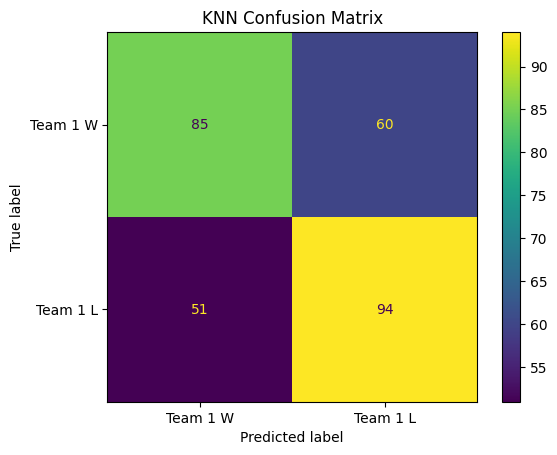

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

knnclf = KNeighborsClassifier(n_neighbors=5)

knnclf.fit(X_train_scaled, y_train)

y_predicted_knnclf = knnclf.predict(X_test_scaled)

knn_comparison = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': y_predicted_knnclf[:10]
})

display(knn_comparison)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

accuracy_knn = accuracy_score(y_test, y_predicted_knnclf)
precision_knn = precision_score(y_test, y_predicted_knnclf)
recall_knn = recall_score(y_test, y_predicted_knnclf)
f1_knn = f1_score(y_test, y_predicted_knnclf)

print("KNN Classification Results")
print("Accuracy:", accuracy_knn)
print("Precision:", precision_knn)
print("Recall:", recall_knn)
print("F1-score:", f1_knn)

classification_results=[]

classification_results = [{
    'Model': 'KNN',
    'Accuracy': accuracy_knn,
    'Precision': precision_knn,
    'Recall': recall_knn,
    'F1': f1_knn
}]

cm_knn = confusion_matrix(y_test, y_predicted_knnclf, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=['Team 1 W', 'Team 1 L']
).plot()

plt.title('KNN Confusion Matrix')
plt.show()

,Actual,Predicted
0,0,1
1,0,1
2,0,1
3,1,1
4,0,1
5,1,1
6,0,0
7,0,0
8,1,1
9,0,1


Logistic Regression Results
Accuracy: 0.6448275862068965
Precision: 0.6346153846153846
Recall: 0.6827586206896552
F1-score: 0.6578073089700996


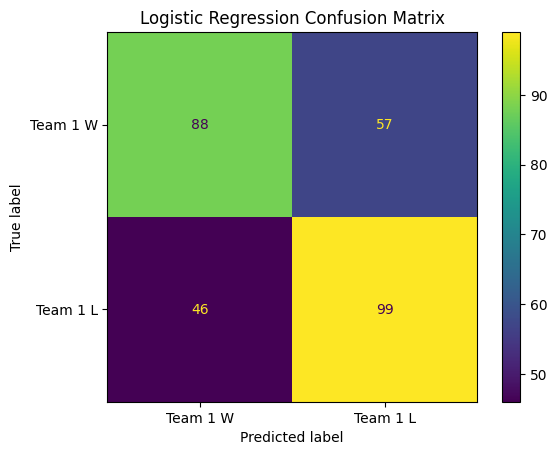

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic.fit(X_train_scaled, y_train)

y_predicted_logistic = logistic.predict(X_test_scaled)

logistic_comparison = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': y_predicted_logistic[:10]
})

display(logistic_comparison)

accuracy_logistic = accuracy_score(y_test, y_predicted_logistic)
precision_logistic = precision_score(y_test, y_predicted_logistic)
recall_logistic = recall_score(y_test, y_predicted_logistic)
f1_logistic = f1_score(y_test, y_predicted_logistic)

print("Logistic Regression Results")
print("Accuracy:", accuracy_logistic)
print("Precision:", precision_logistic)
print("Recall:", recall_logistic)
print("F1-score:", f1_logistic)

classification_results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_logistic,
    'Precision': precision_logistic,
    'Recall': recall_logistic,
    'F1': f1_logistic
})

cm_logistic = confusion_matrix(
    y_test,
    y_predicted_logistic,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=['Team 1 W', 'Team 1 L']
).plot()

plt.title('Logistic Regression Confusion Matrix')
plt.show()

,Actual,Predicted
0,0,0
1,0,1
2,0,1
3,1,1
4,0,1
5,1,1
6,0,0
7,0,0
8,1,0
9,0,1


Support Vector Machine Results
Accuracy: 0.6448275862068965
Precision: 0.6329113924050633
Recall: 0.6896551724137931
F1-score: 0.6600660066006601


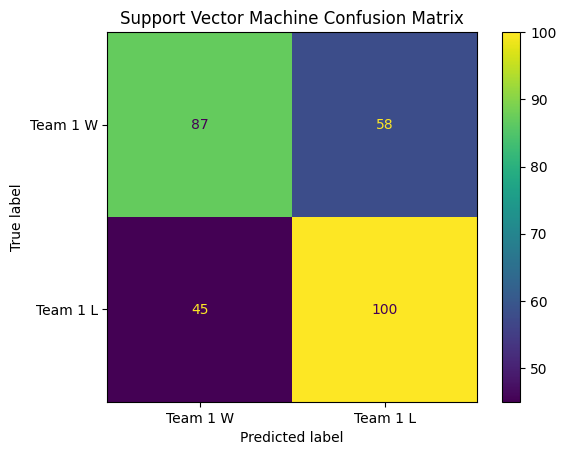

In [ ]:
from sklearn.svm import SVC

svm = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

svm.fit(X_train_scaled, y_train)

y_predicted_svm = svm.predict(X_test_scaled)

svm_comparison = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': y_predicted_svm[:10]
})

display(svm_comparison)

accuracy_svm = accuracy_score(y_test, y_predicted_svm)
precision_svm = precision_score(y_test, y_predicted_svm)
recall_svm = recall_score(y_test, y_predicted_svm)
f1_svm = f1_score(y_test, y_predicted_svm)


classification_results.append({
    'Model': 'Support Vector Machine',
    'Accuracy': accuracy_svm,
    'Precision': precision_svm,
    'Recall': recall_svm,
    'F1': f1_svm
})

print("Support Vector Machine Results")
print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1-score:", f1_svm)

cm_svm = confusion_matrix(y_test, y_predicted_svm, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=['Team 1 W', 'Team 1 L']
).plot()

plt.title('Support Vector Machine Confusion Matrix')
plt.show()

,Actual,Predicted
0,0,1
1,0,1
2,0,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,1,1
9,0,0


Random Forest Results
Accuracy: 0.6172413793103448
Precision: 0.6148648648648649
Recall: 0.6275862068965518
F1-score: 0.621160409556314


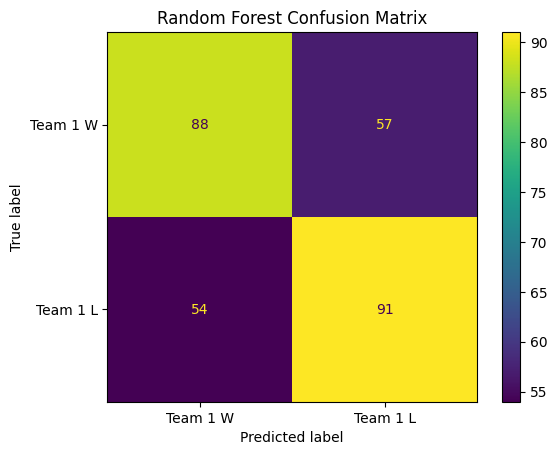

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

forest_clf.fit(X_train, y_train)

y_predicted_forest = forest_clf.predict(X_test)

forest_comparison = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': y_predicted_forest[:10]
})

display(forest_comparison)

accuracy_forest = accuracy_score(y_test, y_predicted_forest)
precision_forest = precision_score(y_test, y_predicted_forest)
recall_forest = recall_score(y_test, y_predicted_forest)
f1_forest = f1_score(y_test, y_predicted_forest)

classification_results.append({
    'Model': 'Random Forest',
    'Accuracy': accuracy_forest,
    'Precision': precision_forest,
    'Recall': recall_forest,
    'F1': f1_forest
})

print("Random Forest Results")
print("Accuracy:", accuracy_forest)
print("Precision:", precision_forest)
print("Recall:", recall_forest)
print("F1-score:", f1_forest)

cm_forest = confusion_matrix(y_test, y_predicted_forest, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_forest,
    display_labels=['Team 1 W', 'Team 1 L']
).plot()

plt.title('Random Forest Confusion Matrix')
plt.show()

,Actual,Predicted
0,0,1
1,0,1
2,0,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,1,0
9,0,1


Gradient Boosting Results
Accuracy: 0.6551724137931034
Precision: 0.6573426573426573
Recall: 0.6482758620689655
F1-score: 0.6527777777777778


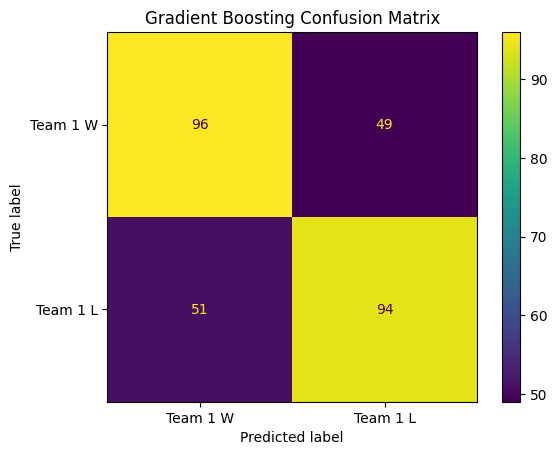

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

boost_clf = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

boost_clf.fit(X_train, y_train)

y_predicted_boost = boost_clf.predict(X_test)

boost_comparison = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': y_predicted_boost[:10]
})

display(boost_comparison)

accuracy_boost = accuracy_score(y_test, y_predicted_boost)
precision_boost = precision_score(y_test, y_predicted_boost)
recall_boost = recall_score(y_test, y_predicted_boost)
f1_boost = f1_score(y_test, y_predicted_boost)

print("Gradient Boosting Results")
print("Accuracy:", accuracy_boost)
print("Precision:", precision_boost)
print("Recall:", recall_boost)
print("F1-score:", f1_boost)

classification_results.append({
    'Model': 'Gradient Boosting',
    'Accuracy': accuracy_boost,
    'Precision': precision_boost,
    'Recall': recall_boost,
    'F1': f1_boost
})

cm_boost = confusion_matrix(y_test, y_predicted_boost, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_boost,
    display_labels=['Team 1 W', 'Team 1 L']
).plot()

plt.title('Gradient Boosting Confusion Matrix')
plt.show()

Gradient Boosting Results
Accuracy: 0.6931034482758621
Precision: 0.7
Recall: 0.6758620689655173
F1-score: 0.6877192982456141


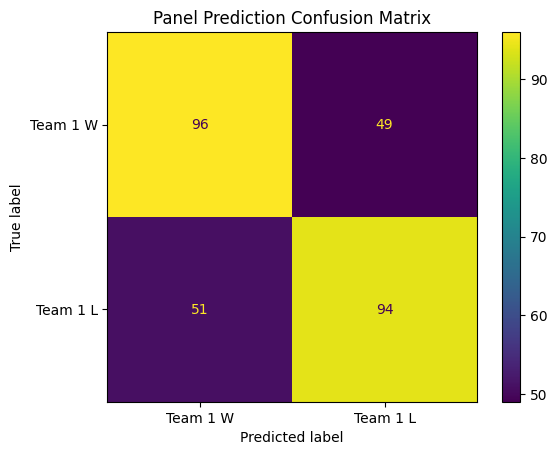

In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'KNN': y_predicted_knnclf,
    'Logistic Regression': y_predicted_logistic,
    'Support Vector Machine': y_predicted_svm,
    'Random Forest': y_predicted_forest,
    'Gradient Boosting': y_predicted_boost
})

comparison["prediction"] = comparison.mode(axis=1)[0].astype(int)

accuracy = accuracy_score(y_test, comparison["prediction"])
precision = precision_score(y_test, comparison["prediction"])
recall = recall_score(y_test,comparison["prediction"])
f1 = f1_score(y_test, comparison["prediction"])

print("Gradient Boosting Results")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

classification_results.append({
    'Model': 'Gradient Boosting',
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1': f1
})

cm = confusion_matrix(y_test, comparison["prediction"], labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_boost,
    display_labels=['Team 1 W', 'Team 1 L']
).plot()

plt.title('Panel Prediction Confusion Matrix')
plt.show()

In [ ]:
def train(
    testdata,
    max_train_year
):

  #X_train = matchups.drop(matchups[matchups["Season"] > max_train_year].index, inplace = True)

  X_train = matchups.drop(columns = ['Season','Team1','Team2','team1_w'])
  y_train = matchups['team1_w']

  from sklearn.preprocessing import StandardScaler

  scaler = StandardScaler()

  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(testdata)

#KNN
  from sklearn.neighbors import KNeighborsClassifier

  knnclf = KNeighborsClassifier(n_neighbors=5)
  knnclf.fit(X_train_scaled, y_train)
  y_predicted_knnclf = knnclf.predict(X_test_scaled)

#Logistic Regression
  from sklearn.linear_model import LogisticRegression

  logistic = LogisticRegression(max_iter=1000,random_state=42)
  logistic.fit(X_train_scaled, y_train)
  y_predicted_logistic = logistic.predict(X_test_scaled)

  #Support Vector Machine
  from sklearn.svm import SVC

  svm = SVC(kernel='rbf',C=1.0,gamma='scale',random_state=42)
  svm.fit(X_train_scaled, y_train)
  y_predicted_svm = svm.predict(X_test_scaled)

  #Random Forest
  from sklearn.ensemble import RandomForestClassifier

  forest_clf = RandomForestClassifier(n_estimators=100,random_state=42)
  forest_clf.fit(X_train, y_train)
  y_predicted_forest = forest_clf.predict(testdata)

  #Gradient Boosting
  from sklearn.ensemble import GradientBoostingClassifier

  boost_clf = GradientBoostingClassifier(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)
  boost_clf.fit(X_train, y_train)
  y_predicted_boost = boost_clf.predict(testdata)

  panel = pd.DataFrame({
      'KNN': y_predicted_knnclf,
      'Logistic Regression': y_predicted_logistic,
      'Support Vector Machine': y_predicted_svm,
      'Random Forest': y_predicted_forest,
      'Gradient Boosting': y_predicted_boost})

  panel["prediction"] = panel.mode(axis=1)[0].astype(int)

  return panel


In [ ]:
def predict(
    matchups
):

  max_train_year = matchups["season"].max() - 1
  matchups["team_name"] = matchups["team_name"].str.lower()

  team_ids = pd.read_csv("MTeamSpellings.csv")

  matchups = matchups.merge(
      team_ids,
      how="left",
      left_on=["team_name"],
      right_on=["TeamNameSpelling"]
  ).drop(columns=["TeamNameSpelling"])

  missing_teams = matchups.loc[
    matchups["TeamID"].isnull(), "team_name"
  ].unique()

  assert len(missing_teams) == 0, f"Missing TeamIDs for: {missing_teams}"

  matchups = matchups.merge(
      seasonstats,
      how="left",
      left_on=["season","TeamID"],
      right_on=["Season","TeamID"]
  )

  team1 = matchups[matchups.index % 2 == 0].copy().reset_index(drop=True)
  team2 = matchups[matchups.index % 2 == 1].copy().reset_index(drop=True)

  thisround_matchups = team1.merge(
      team2,
      how="left",
      left_index=True,
      right_index=True,
      suffixes=["_1","_2"]
  )

  thisround_train = thisround_matchups.drop(
      columns=[
          "season_1","season_2",
          "team_name_1","team_name_2",
          "TeamID_1","TeamID_2",
          "Season_1","Season_2"
          ]).copy()

  # Fixed shape checks to check row count and corrected block indentation
  rows = thisround_matchups.shape[0]
  if rows == 32:
    thisround_train.insert(0,"DayNum" , 136.5)
  elif rows == 16:
    thisround_train.insert(0,"DayNum" , 138.5)
  elif rows == 8:
    thisround_train.insert(0,"DayNum" , 143.5)
  elif rows == 4:
    thisround_train.insert(0,"DayNum" , 145.5)
  elif rows == 2:
    thisround_train.insert(0,"DayNum" , 152)
  elif rows == 1:
    thisround_train.insert(0,"DayNum" , 154)
  else:
    thisround_train.insert(0,"DayNum" , 136.5)

  panel_predictions = train(thisround_train,max_train_year)

  predictions = panel_predictions["prediction"]

  thisround_matchups = thisround_matchups.merge(
      predictions,
      how="left",
      left_index=True,
      right_index=True)

  thisround_matchups["predicted_winner"] = (thisround_matchups["prediction"] * thisround_matchups["TeamID_1"]) + ((1 - thisround_matchups["prediction"]) * thisround_matchups["TeamID_2"])

  thisround_matchups["predicted_winner_name"] = thisround_matchups["team_name_1"].where(
    thisround_matchups["prediction"] == 1,
    thisround_matchups["team_name_2"]
  )

  nextround_predicted = thisround_matchups[
    ["predicted_winner", "predicted_winner_name"]
  ].copy()

  nextround_predicted.insert(0,"season",matchups["Season"].max())
  nextround_predicted.drop(columns = ["predicted_winner"],inplace = True)
  nextround_predicted.rename(columns = {"predicted_winner_name":"team_name"},inplace = True)

  return nextround_predicted

In [ ]:
ro64 = pd.read_csv("2025matchups.csv")

ro32 = predict(ro64)
sweet16 = predict(ro32)
elite8 = predict(sweet16)
final4 = predict(elite8)
championship = predict(final4)
champion = predict(championship)

display(ro32)
display(sweet16)
display(elite8)
display(final4)
display(championship)
display(champion)

,season,team_name
0,2025,auburn
1,2025,creighton
2,2025,uc san diego
3,2025,yale
4,2025,north carolina
5,2025,iowa state
6,2025,marquette
7,2025,michigan state
8,2025,florida
9,2025,uconn


,season,team_name
0,2025,auburn
1,2025,yale
2,2025,iowa state
3,2025,michigan state
4,2025,florida
5,2025,maryland
6,2025,texas tech
7,2025,st. john's
8,2025,duke
9,2025,arizona


,season,team_name
0,2025,auburn
1,2025,michigan state
2,2025,florida
3,2025,texas tech
4,2025,duke
5,2025,alabama
6,2025,houston
7,2025,kentucky


,season,team_name
0,2025,auburn
1,2025,florida
2,2025,alabama
3,2025,houston


,season,team_name
0,2025,florida
1,2025,houston


,season,team_name
0,2025,florida
